<a href="https://colab.research.google.com/github/api-sage/systems_stochastic_processes/blob/main/project3/HW3_Starter_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 18-751 Applied Stochastic Processes — Homework 3

## Coding Starter Notebook — Fall 2026


Complete every `TODO`, generate all required figures and tables, and write each short discussion in the indicated Markdown cell.


### Instructions

- Keep the supplied random seed so that your work is reproducible.
- Use vectorized NumPy operations where practical.
- Label every plot clearly and include a legend when requested.
- Report empirical variances consistently (the starter uses `ddof=0`).
- Before submission, restart the kernel and run all cells from top to bottom.


In [1]:
# Run this cell first.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gamma, norm

SEED = 2027
rng = np.random.default_rng(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.titlesize"] = 12

print(f"Random seed: {SEED}")


Random seed: 2027


---

## Task 1 — Empirical vs. Theoretical PMF for Dice Sums (10 points)

1. Simulate $N=10{,}000$ independent rolls of two fair dice and form $W=X+Y$.
2. Compute the empirical PMF of $W$ on $\{2,\ldots,12\}$.
3. Compute the theoretical PMF by enumerating all 36 ordered outcomes.
4. Create **Figure 1**: empirical PMF as bars with the theoretical PMF overlaid using markers and a line.
5. Write a 3–5 sentence discussion about agreement and the effect of $N$ on convergence.


In [2]:
# Task 1(a): simulate the dice sums.
N = 10_000
sum_values = np.arange(2, 13)

X = rng.integers(1, 7, size=N)
Y = rng.integers(1, 7, size=N)
W = X + Y


In [3]:
# Task 1(b–c): compute the empirical and theoretical PMFs.

empirical_pmf = np.array([np.mean(W == value) for value in sum_values])
all_outcomes = np.add.outer(np.arange(1, 7), np.arange(1, 7))
theoretical_pmf = np.array([np.count_nonzero(all_outcomes == value) / 36 for value in sum_values])

# Suggested check after completing the TODOs:
# assert empirical_pmf.shape == theoretical_pmf.shape == sum_values.shape
# assert np.isclose(empirical_pmf.sum(), 1.0)
# assert np.isclose(theoretical_pmf.sum(), 1.0)


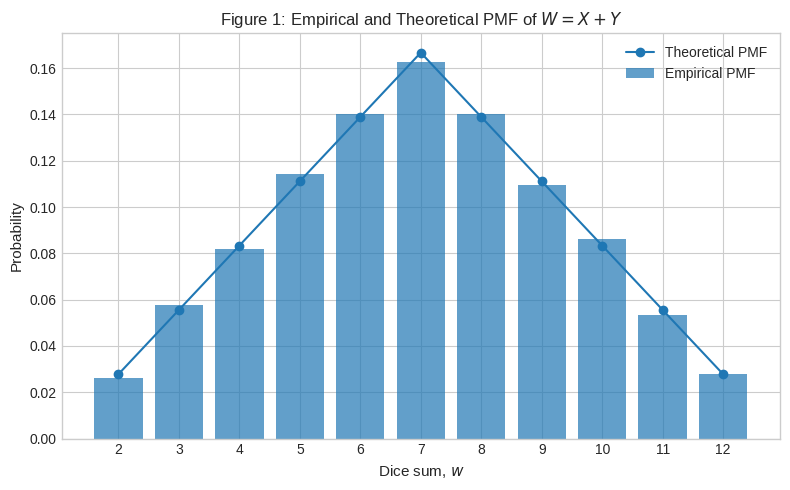

In [4]:
# Task 1(d): Figure 1.
fig, ax = plt.subplots()

ax.bar(sum_values, empirical_pmf, label="Empirical PMF", alpha=0.7)
ax.plot(sum_values, theoretical_pmf, marker="o", label="Theoretical PMF")

ax.set_xlabel("Dice sum, $w$")
ax.set_ylabel("Probability")
ax.set_title("Figure 1: Empirical and Theoretical PMF of $W=X+Y$")
ax.set_xticks(sum_values)

ax.legend()
plt.tight_layout()
plt.show()


### Task 1 discussion (3–5 sentences)

The empirical PMF follows the theoretical triangular pattern, with the largest probability at a sum of 7 and decreasing probabilities toward 2 and 12. The simulated probabilities are close to their theoretical values, although small differences occur because the experiment uses a finite number of rolls. Increasing $N$ would reduce these sampling fluctuations and make the empirical PMF more closely approximate the theoretical PMF. This convergence is consistent with the law of large numbers.

---

## Task 2 — Sum of Exponentials $\Rightarrow$ Gamma (10 points)

For $\lambda=1$ and $n\in\{1,2,5\}$, generate $M=10{,}000$ independent realizations of

$$T_n=\sum_{i=1}^{n}Y_i, \qquad Y_i\sim\operatorname{Exponential}(\lambda).$$

For each $n$, produce a normalized histogram and overlay the $\operatorname{Gamma}(k=n,\text{ rate }\lambda)$ density. In SciPy, use `a=n` and `scale=1/lambda_rate`. Then create **Table 1** comparing empirical and theoretical means and variances, followed by a 4–6 sentence discussion.


In [5]:
# Task 2(a): simulate T_n for each n.
lambda_rate = 1.0
n_values_exp = [1, 2, 5]
M = 10_000

# Store each array of M totals under its corresponding n.
exponential_sums = {}

for n in n_values_exp:
    exponential_samples = rng.exponential(scale=1 / lambda_rate, size=(M, n))
    exponential_sums[n] = exponential_samples.sum(axis=1)

print("Completed n values:", list(exponential_sums))


Completed n values: [1, 2, 5]


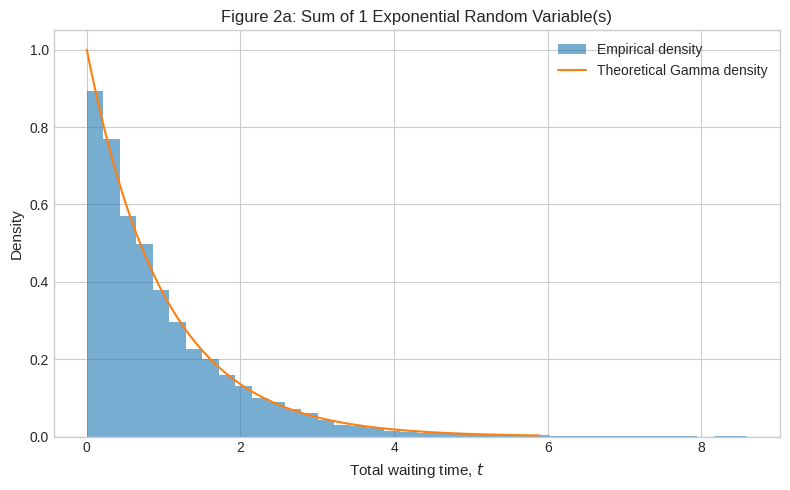

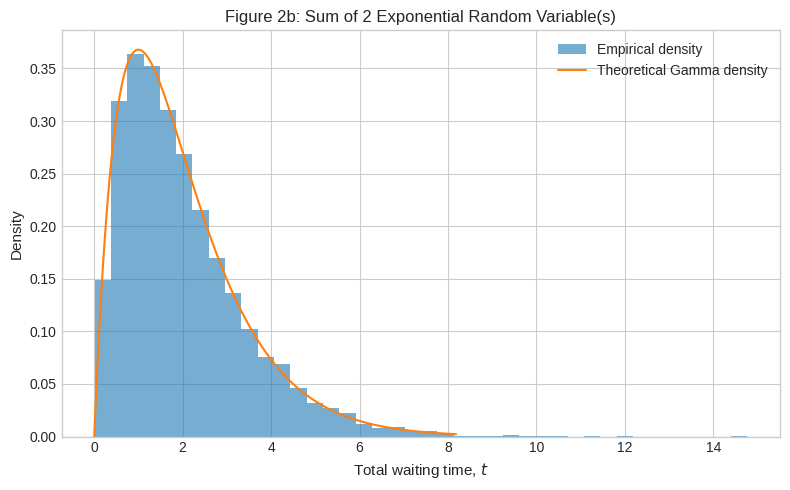

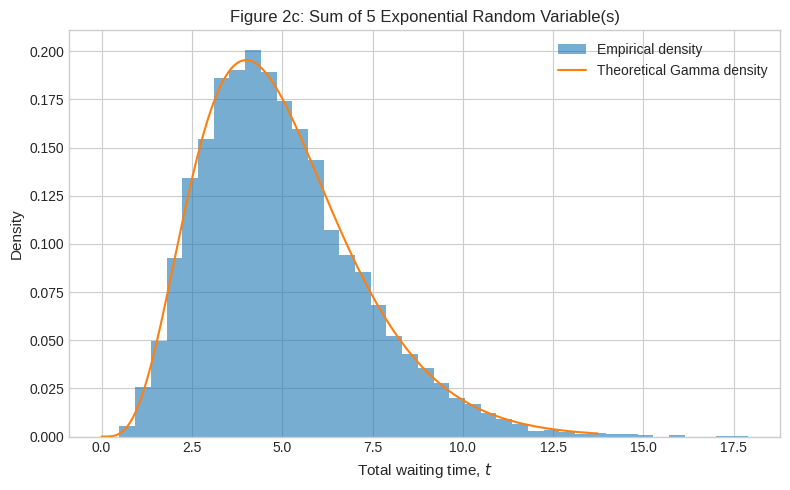

In [6]:
# Task 2(b–c): Figures 2a–2c.
for n in n_values_exp:
    if n not in exponential_sums:
        print(f"Complete the simulation TODO before plotting n={n}.")
        continue

    samples = exponential_sums[n]
    x_grid = np.linspace(0, np.percentile(samples, 99.5) * 1.1, 500)
    theoretical_density = gamma.pdf(x_grid, a=n, scale=1 / lambda_rate)

    fig, ax = plt.subplots()
    ax.hist(samples, bins=40, density=True, alpha=0.6, label="Empirical density")
    ax.plot(x_grid, theoretical_density, label="Theoretical Gamma density")
    ax.set_xlabel(r"Total waiting time, $t$")
    ax.set_ylabel("Density")
    figure_label = {1: "2a", 2: "2b", 5: "2c"}[n]
    ax.set_title(f"Figure {figure_label}: Sum of {n} Exponential Random Variable(s)")
    ax.legend()
    plt.tight_layout()
    plt.show()


In [7]:
# Task 2(d): Table 1.
task2_rows = []

for n in n_values_exp:
    if n not in exponential_sums:
        continue
    samples = exponential_sums[n]

    task2_rows.append({
        "n": n,
        "Empirical mean": np.mean(samples),
        "Theoretical mean": n / lambda_rate,
        "Empirical variance": np.var(samples, ddof=0),
        "Theoretical variance": n / lambda_rate**2,
    })

table1 = pd.DataFrame(task2_rows)
table1


,n,Empirical mean,Theoretical mean,Empirical variance,Theoretical variance
0,1,0.986403,1.0,0.974532,1.0
1,2,2.004959,2.0,2.031436,2.0
2,5,4.979468,5.0,4.868242,5.0


### Task 2 discussion (4–6 sentences)

The simulated distributions are well described by their corresponding Gamma densities, with the agreement reflecting that a sum of $n$ independent Exponential random variables with common rate $\lambda$ has a Gamma distribution with shape $n$ and rate $\lambda$. The theoretical mean and variance are $n/\lambda$ and $n/\lambda^2$, respectively, and the empirical values are close to these quantities. As $n$ increases, the sum is centered at a larger mean while its standard deviation grows only as $\sqrt{n}/\lambda$. Consequently, the distribution becomes more concentrated relative to its mean and appears less right-skewed. Finite-sample differences between the histograms, densities, and table values are due to random sampling variability.

---

## Task 3 — CLT Demonstration with Sample Means (10 points)

For $n\in\{1,5,30\}$, generate $M=10{,}000$ sample means

$$\overline U_n=\frac{1}{n}\sum_{i=1}^{n}U_i, \qquad U_i\sim\operatorname{Uniform}(0,1).$$

For each $n$, overlay the normalized histogram with the density of
$\mathcal N\!\left(0.5,1/(12n)\right)$. Create **Table 2** comparing empirical and theoretical means and variances, then write a 4–6 sentence discussion.


In [8]:
# Task 3(a): simulate M sample means for each n.
n_values_clt = [1, 5, 30]
uniform_sample_means = {}

for n in n_values_clt:
    uniform_samples = rng.uniform(0, 1, size=(M, n))
    uniform_sample_means[n] = uniform_samples.mean(axis=1)

print("Completed n values:", list(uniform_sample_means))


Completed n values: [1, 5, 30]


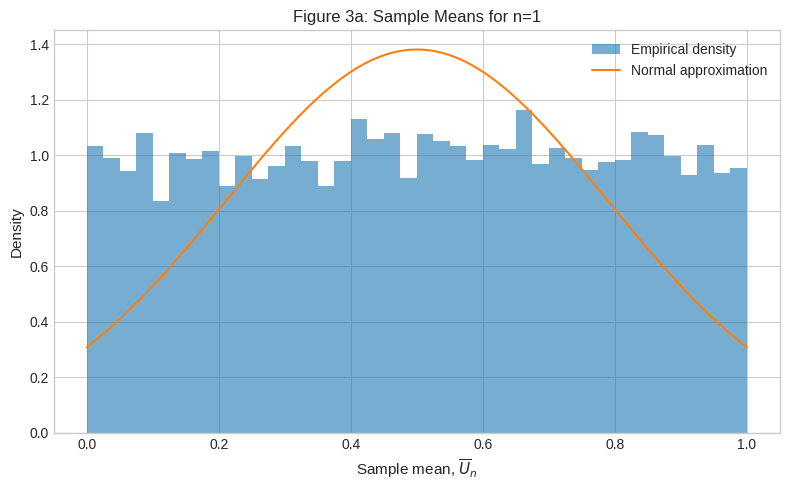

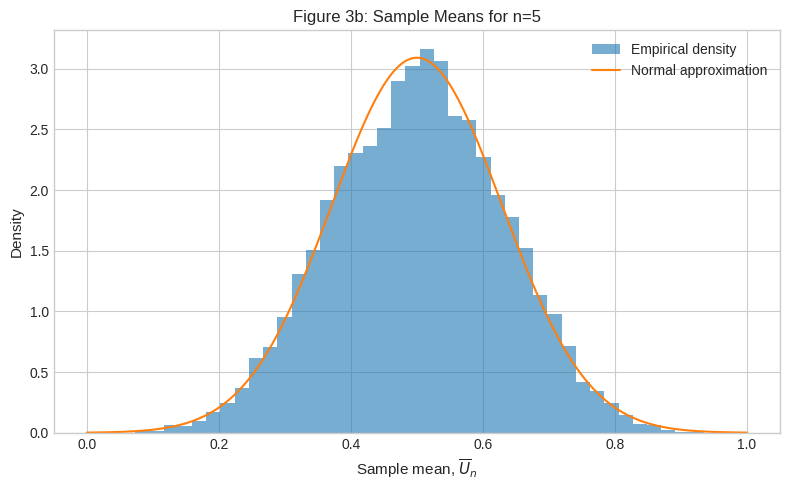

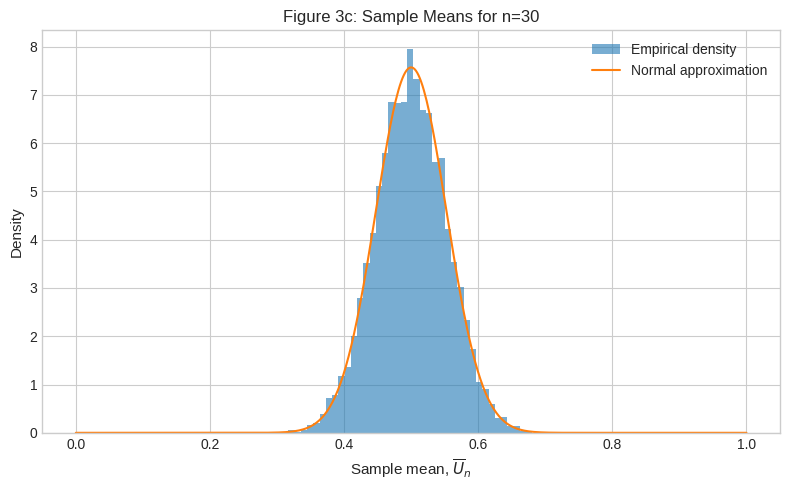

In [9]:
# Task 3(b–c): Figures 3a–3c.
mu_uniform = 0.5

for n in n_values_clt:
    if n not in uniform_sample_means:
        print(f"Complete the simulation TODO before plotting n={n}.")
        continue

    sample_means = uniform_sample_means[n]
    theoretical_variance = 1 / (12 * n)
    theoretical_sd = np.sqrt(theoretical_variance)
    x_grid = np.linspace(0, 1, 500)
    normal_density = norm.pdf(x_grid, loc=mu_uniform, scale=theoretical_sd)

    fig, ax = plt.subplots()
    ax.hist(sample_means, bins=40, density=True, alpha=0.6, label="Empirical density")
    ax.plot(x_grid, normal_density, label="Normal approximation")
    ax.set_xlabel(r"Sample mean, $\overline{U}_n$")
    ax.set_ylabel("Density")
    figure_label = {1: "3a", 5: "3b", 30: "3c"}[n]
    ax.set_title(f"Figure {figure_label}: Sample Means for n={n}")
    ax.legend()
    plt.tight_layout()
    plt.show()


In [10]:
# Task 3(d): Table 2.
task3_rows = []

for n in n_values_clt:
    if n not in uniform_sample_means:
        continue
    sample_means = uniform_sample_means[n]

    task3_rows.append({
        "n": n,
        "Empirical mean": np.mean(sample_means),
        "Theoretical mean": mu_uniform,
        "Empirical variance": np.var(sample_means, ddof=0),
        "Theoretical variance": 1 / (12 * n),
    })

table2 = pd.DataFrame(task3_rows)
table2


,n,Empirical mean,Theoretical mean,Empirical variance,Theoretical variance
0,1,0.502417,0.5,0.082223,0.083333
1,5,0.501016,0.5,0.016679,0.016667
2,30,0.499716,0.5,0.002845,0.002778


### Task 3 discussion (4–6 sentences)

For $n=1$, the sample means follow the original Uniform$(0,1)$ distribution, which is not Normal. As $n$ increases to 5 and then 30, the histograms become more symmetric and more closely resemble the overlaid Normal densities. The empirical means remain close to the theoretical value of 0.5 for all three sample sizes. The variance decreases from $1/12$ to $1/60$ and then $1/360$, in agreement with the theoretical $1/(12n)$ scaling. These results illustrate how averaging independent observations leads to a distribution that is increasingly well approximated by a Normal distribution.

---

## Task 4 — Applied Aggregation: 30-Day Rainfall (10 points)

Let the independent daily rainfall amounts satisfy $R_i\sim\operatorname{Exponential}(\lambda=0.5)$ and define

$$R_{30}=\sum_{i=1}^{30}R_i.$$

For $\tau\in\{60,70,80\}$, estimate $\mathbb P(R_{30}\geq\tau)$ by simulation and approximate it using the CLT with

$$\mu=\frac{30}{\lambda}, \qquad \sigma^2=\frac{30}{\lambda^2}.$$

Create **Figure 4** and **Table 3**, then write a 3–5 sentence discussion.


In [11]:
# Task 4(a–b): simulate monthly rainfall totals.
rain_lambda = 0.5
days = 30
rain_trials = 10_000
thresholds = np.array([60, 70, 80])

daily_rainfall = rng.exponential(scale=1 / rain_lambda, size=(rain_trials, days))
R30 = daily_rainfall.sum(axis=1)

mc_probabilities = np.mean(R30[:, np.newaxis] >= thresholds, axis=0)


In [12]:
# Task 4(c): CLT approximation.

clt_mean = days / rain_lambda
clt_variance = days / rain_lambda**2
clt_sd = np.sqrt(clt_variance)

z_scores = (thresholds - clt_mean) / clt_sd
clt_probabilities = norm.sf(z_scores)


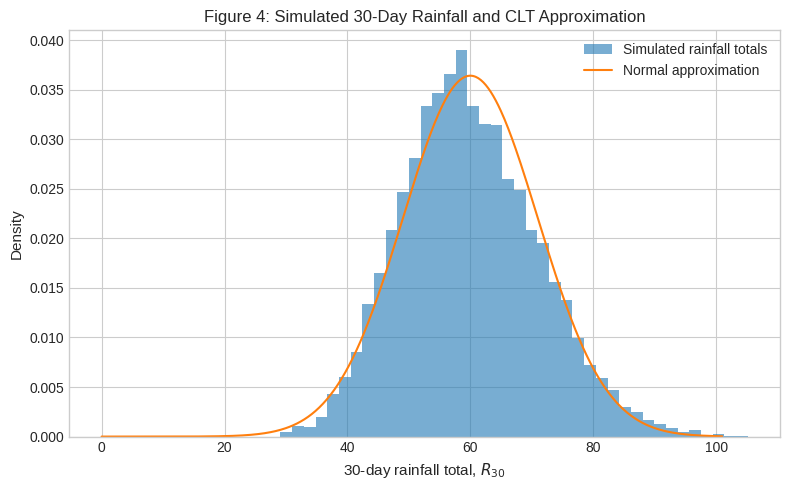

In [13]:
# Task 4(d): Figure 4.
fig, ax = plt.subplots()

ax.hist(R30, bins=40, density=True, alpha=0.6, label="Simulated rainfall totals")
x_grid = np.linspace(0, np.percentile(R30, 99.8) * 1.05, 500)
normal_density = norm.pdf(x_grid, loc=clt_mean, scale=clt_sd)
ax.plot(x_grid, normal_density, label="Normal approximation")

ax.set_xlabel(r"30-day rainfall total, $R_{30}$")
ax.set_ylabel("Density")
ax.set_title("Figure 4: Simulated 30-Day Rainfall and CLT Approximation")
ax.legend()
plt.tight_layout()
plt.show()


In [14]:
# Task 4(e): Table 3.

table3 = pd.DataFrame({
    "Threshold": thresholds,
    "Monte Carlo estimate": mc_probabilities,
    "CLT approximation": clt_probabilities,
    "Absolute error": np.abs(mc_probabilities - clt_probabilities),
})
table3


,Threshold,Monte Carlo estimate,CLT approximation,Absolute error
0,60,0.4695,0.500000,0.030500
1,70,0.1846,0.180655,0.003945
2,80,0.0436,0.033945,0.009655


### Task 4 discussion (3–5 sentences)

The simulated distribution of the 30-day total is close to the overlaid Normal approximation, although the rainfall totals retain some right skew. The CLT estimate is close to the Monte Carlo estimate at a threshold of 70, while the differences are larger at thresholds of 60 and 80. Some variation also comes from using a finite number of simulated months. With 30 independent daily contributions, the CLT gives a useful approximation, but the remaining skewness means that it does not give exact exceedance probabilities.